# 05 — k-Nearest Neighbours

> Classifying a new case by letting the most similar known cases vote.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

Lessons 01–04 all predicted a **number**: grams of CO2, dollars of GDP. This
lesson is the first to predict a **category**.

A telecommunications provider has split its customers into four groups by how
they use the service:

| `custcat` | Group |
|---|---|
| 1 | Basic Service |
| 2 | E-Service |
| 3 | Plus Service |
| 4 | Total Service |

If demographic data alone — region, age, income, marital status and so on — can
predict which group a customer belongs to, the company can tailor offers to
prospective customers before they have used anything.

The input is eleven demographic columns; the output is one of four labels. A
good answer is a model that puts new customers in the right group noticeably
more often than guessing would.

Because the output is a label, the way results are measured changes too. There
is no "error of 24 g/km" any more: a prediction is either the right group or it
is not, so the main measure is **accuracy** — the share of customers placed in
the right group.

## 2. Intuition

Similar customers tend to buy similar plans. So to classify a new customer, find
the **K existing customers most similar to them** and let those K vote: the
group that appears most often among them is the prediction.

"Most similar" means closest, once every customer is treated as a point in space
with one axis per feature. That makes two things matter a great deal:

- **How distance is measured** — and in particular whether one feature's units
  swamp all the others.
- **K** — which is chosen by hand, and can change the answer. The small example
  below shows how.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split and the cross-validation folds are the
# same on every run, and the numbers in README.md are the numbers you get.
RANDOM_SEED = 4

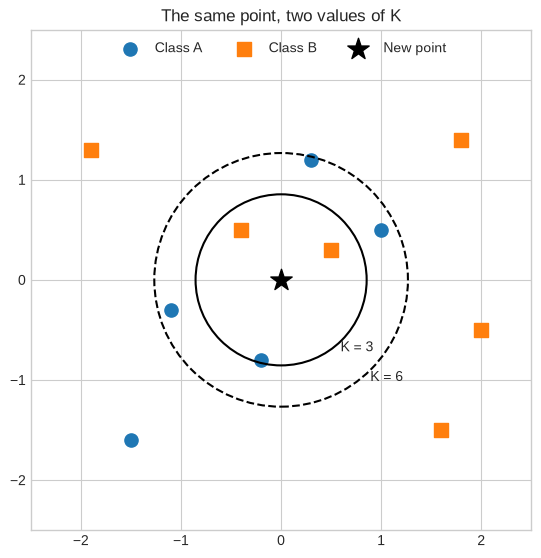

In [2]:
# A hand-made example: eleven labelled points and one new point at the origin.
class_a = np.array([[-0.2, -0.8], [1.0, 0.5], [-1.1, -0.3], [0.3, 1.2], [-1.5, -1.6]])
class_b = np.array([[0.5, 0.3], [-0.4, 0.5], [1.8, 1.4], [2.0, -0.5], [-1.9, 1.3], [1.6, -1.5]])
new_point = np.array([0.0, 0.0])

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(*class_a.T, s=90, color="tab:blue", label="Class A")
ax.scatter(*class_b.T, s=90, color="tab:orange", marker="s", label="Class B")
ax.scatter(*new_point, s=260, color="black", marker="*", label="New point", zorder=3)

# A circle through the 3rd and the 6th nearest neighbour marks each neighbourhood.
all_points = np.vstack([class_a, class_b])
distances = np.sort(np.linalg.norm(all_points - new_point, axis=1))
for k, style in [(3, "-"), (6, "--")]:
    ax.add_patch(
        plt.Circle(new_point, distances[k - 1] + 0.03, fill=False, linestyle=style, linewidth=1.5)
    )
    ax.annotate(f"K = {k}", (distances[k - 1] * 0.72, -distances[k - 1] * 0.72 - 0.12))

ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_aspect("equal")
ax.set_title("The same point, two values of K")
ax.legend(loc="upper center", ncol=3)
plt.show()

With **K = 3** the neighbourhood holds two B's and one A, so the new point is
classed as **B**. Widen it to **K = 6** and it holds two B's and four A's, so the
same point becomes **A**.

Nothing about the data changed; only K did. K is a setting the model cannot learn
for itself, and choosing it well is most of the work in this lesson.

## 3. The mathematics

**Distance.** Each customer is a vector $\mathbf{x} \in \mathbb{R}^n$ of $n$
features. The distance between two customers is the ordinary straight-line
(Euclidean) distance:

$$
d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{n} \left( x_j - x'_j \right)^2}
$$

**Prediction — a majority vote.** Let $N_K(\mathbf{x})$ be the $K$ training
points closest to $\mathbf{x}$. The predicted class is the one that appears most
often among them:

$$
\hat{y} = \underset{c}{\arg\max} \sum_{i \in N_K(\mathbf{x})} \mathbb{1}\left( y^{(i)} = c \right)
$$

where $\mathbb{1}(\cdot)$ is 1 when its condition holds and 0 otherwise.

**There is no cost function, and nothing is fitted.** This is the real break
from lessons 01–04. Linear regression searched for the parameters that minimise
a cost; KNN has no parameters at all. `fit()` simply stores the training set,
and every piece of work happens at prediction time, when the new point is
compared against all $m$ stored points. That is why KNN is called a *lazy*
learner: training is free, prediction is slow, and the whole training set must
be kept around.

**Why features must be scaled.** The distance adds up squared differences
feature by feature, so a feature measured in large units dominates it. In this
dataset income runs into the hundreds while marital status is 0 or 1; unscaled,
a difference of a few thousand dollars of income would outweigh every other
feature combined. Standardising each feature fixes that:

$$
z_j = \frac{x_j - \mu_j}{\sigma_j}
$$

where $\mu_j$ and $\sigma_j$ are the mean and standard deviation of feature $j$
**on the training set**. After this, every feature is measured in "standard
deviations from typical", and each gets an equal say in the distance.

**K is a hyperparameter.** Small K follows individual training points closely —
with $K = 1$ every training point is its own nearest neighbour, so training
accuracy is a meaningless 100%. Large K averages over wide neighbourhoods and
eventually just predicts the most common class. The right K lies in between and
has to be found by measuring on data the model has not seen.

**Ties.** With four classes, a vote can tie for any K — for instance 2–2 with
$K = 4$. scikit-learn then picks the tied class that comes first in its list of
classes, which in practice favours the lower-numbered group.

## 4. The data

Customer records from a telecommunications provider, 1,000 rows, as supplied with
the course.

In [3]:
df = pd.read_csv("data/teleCust1000t.csv")

# take a look at the dataset
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64,4,5,0,0,2,1
1,3,11,33,1,7,136,5,5,0,0,6,4
2,3,68,52,1,24,116,1,29,0,1,2,3
3,2,33,33,0,12,33,2,0,0,1,1,1
4,2,23,30,1,9,30,1,2,0,0,4,3


| Column | Meaning |
|---|---|
| `region` | Region code, 1–3 |
| `tenure` | Months as a customer |
| `age` | Age in years |
| `marital` | 1 = married, 0 = not |
| `address` | Years at current address |
| `income` | Household income, thousands |
| `ed` | Education level, 1–5 |
| `employ` | Years with current employer |
| `retire` | 1 = retired |
| `gender` | Coded 0 / 1 |
| `reside` | Number of people in the household |
| `custcat` | **Target** — customer group, 1–4 |

How many customers are in each group:

In [4]:
df["custcat"].value_counts().sort_index()

custcat
1    266
2    217
3    281
4    236
Name: count, dtype: int64

266 Basic, 217 E-Service, 281 Plus and 236 Total Service. The classes are close
to balanced, which fixes a floor for every result that follows: guessing at
random is right 25% of the time, and always guessing the largest group (Plus
Service) is right 28% of the time. A model is only useful to the extent that it
beats that.

In [5]:
df.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
region,2.02,0.82,1.0,3.0
tenure,35.53,21.36,1.0,72.0
age,41.68,12.56,18.0,77.0
marital,0.50,0.50,0.0,1.0
address,11.55,10.09,0.0,55.0
income,77.54,107.04,9.0,1668.0
ed,2.67,1.22,1.0,5.0
employ,10.99,10.08,0.0,47.0
retire,0.05,0.21,0.0,1.0
gender,0.52,0.50,0.0,1.0


No missing values, and the columns sit on wildly different scales: `marital`
runs from 0 to 1, `income` from 9 to 1,668. Income is also heavily skewed:

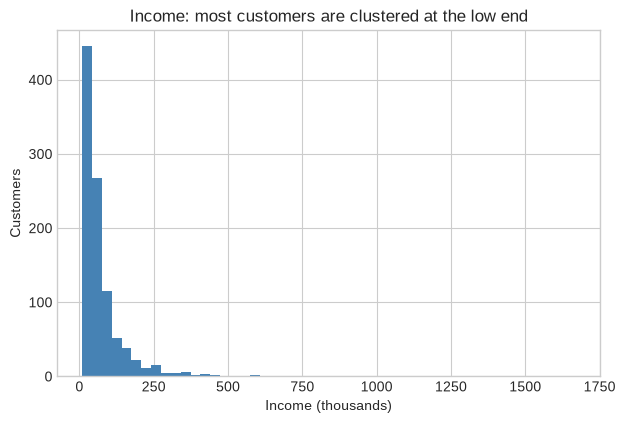

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df["income"], bins=50, color="steelblue")
ax.set_xlabel("Income (thousands)")
ax.set_ylabel("Customers")
ax.set_title("Income: most customers are clustered at the low end")
plt.show()

Most customers earn under 100, and a handful are far out to the right. In raw
units, distances between customers would be mostly distances in income — the
reason section 3 insists on standardising.

### Feature set and labels

All eleven demographic columns as features, `custcat` as the label.

In [7]:
feature_cols = [
    "region", "tenure", "age", "marital", "address", "income",
    "ed", "employ", "retire", "gender", "reside",
]

X = df[feature_cols].to_numpy(dtype=float)
y = df["custcat"].to_numpy()

X[0:5]

array([[  2.,  13.,  44.,   1.,   9.,  64.,   4.,   5.,   0.,   0.,   2.],
       [  3.,  11.,  33.,   1.,   7., 136.,   5.,   5.,   0.,   0.,   6.],
       [  3.,  68.,  52.,   1.,  24., 116.,   1.,  29.,   0.,   1.,   2.],
       [  2.,  33.,  33.,   0.,  12.,  33.,   2.,   0.,   0.,   1.,   1.],
       [  2.,  23.,  30.,   1.,   9.,  30.,   1.,   2.,   0.,   0.,   4.]])

### Creating train and test datasets

80% of customers to fit on, 20% held back. The test set is touched **once**, at
the very end — section 6 explains why that rule matters more here than in any
earlier lesson.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)

print("Train set:", X_train.shape, y_train.shape)
print("Test set: ", X_test.shape, y_test.shape)

Train set: (800, 11) (800,)
Test set:  (200, 11) (200,)


### Standardising the features

The scaler learns each feature's mean and standard deviation from the
**training** rows only, then applies those same numbers to the test rows.

Fitting it on the full dataset before splitting would let the test customers
shape the mean and spread used to scale the training customers — a small leak,
but a leak: the test set would no longer be entirely unseen.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Every training column now has mean 0 and standard deviation 1.
print("train means:", X_train_s.mean(axis=0).round(2))
print("train stds: ", X_train_s.std(axis=0).round(2))

train means: [ 0.  0.  0. -0.  0. -0.  0. -0.  0. -0. -0.]
train stds:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Modeling

Starting with K = 4.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

k = 4
neigh = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
neigh

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


That `fit()` did no optimisation — as section 3 said, it stored the 800 training
customers. The work happens now, in `predict()`:

In [11]:
yhat = neigh.predict(X_test_s)

print("predicted:", yhat[0:10])
print("actual:   ", y_test[0:10])

predicted: [1 1 3 2 4 3 3 2 2 4]
actual:    [4 1 1 2 4 4 3 1 3 4]


Comparing predictions against the **test** labels, row for row. A few match, a
few do not; one glance at ten rows says nothing reliable, so to the numbers.

In [12]:
from sklearn import metrics

for k in [4, 6]:
    neigh_k = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    train_acc = metrics.accuracy_score(y_train, neigh_k.predict(X_train_s))
    test_acc = metrics.accuracy_score(y_test, neigh_k.predict(X_test_s))
    print(f"K = {k}:  train accuracy {train_acc:.4f}   test accuracy {test_acc:.4f}")

K = 4:  train accuracy 0.5475   test accuracy 0.3200
K = 6:  train accuracy 0.5125   test accuracy 0.3100


Two things stand out.

**The gap.** Training accuracy is around 0.5, test accuracy around 0.3. Scoring
a KNN model on its own training rows is flattering by construction: each
training customer's neighbourhood includes *itself*, which always votes for the
right answer. Only the test score says anything about new customers.

**The level.** Around 0.3 test accuracy sounds poor, but "poor" needs a
reference point. The honest one is a model that ignores every feature:

In [13]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_acc = metrics.accuracy_score(y_test, baseline.predict(X_test))

print(f"Always predict group {baseline.predict(X_test[:1])[0]}:  test accuracy {baseline_acc:.4f}")

Always predict group 3:  test accuracy 0.2700


Always answering "Plus Service" scores 0.27 on this test set. K = 4 beats that
by only a few points — the features carry *some* information about the customer
group, but not much. Whether a better K helps is the question for section 6.

## 6. Results and interpretation

### Choosing K

The obvious approach is to try K = 1, 2, 3, … , score each on the test set, and
keep the best. It is also a trap. Once the test set has been used to *choose* K,
it has become part of training: the winning score is the best of many attempts
on the same 200 customers, and is partly luck. The test set would no longer be
unseen, and its score would no longer be honest.

The fix is the one used in the Tehran house price project: **5-fold
cross-validation on the training set only**. Split the 800 training customers
into five parts, fit on four and score on the fifth, rotate five times, and
average. Every K is judged without the test set ever being looked at.

Scaling has to happen *inside* each fold — otherwise the held-out fold would
leak into the scaler, exactly the problem from section 4. A `Pipeline` bundles
scaler and classifier so that every `fit` refits both.

For comparison only, the loop below also records each K's test score — to show
how misleading choosing on it would have been.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

Ks = range(1, 51)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

rows = []
for k in Ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")

    model.fit(X_train, y_train)
    rows.append(
        {
            "K": k,
            "train": metrics.accuracy_score(y_train, model.predict(X_train)),
            "cv mean": cv_scores.mean(),
            "cv std": cv_scores.std(),
            "test (not used to choose)": metrics.accuracy_score(y_test, model.predict(X_test)),
        }
    )

results = pd.DataFrame(rows).set_index("K")
results.loc[[1, 2, 4, 6, 9, 15, 20, 25, 30, 40, 50]].round(4)

,train,cv mean,cv std,test (not used to choose)
K,,,,
1,1.0000,0.2687,0.0213,0.300
2,0.6150,0.2762,0.0199,0.305
4,0.5475,0.3087,0.0337,0.320
6,0.5125,0.3325,0.0423,0.310
9,0.4988,0.3263,0.0436,0.335
15,0.4538,0.3600,0.0429,0.325
20,0.4675,0.3612,0.0443,0.330
25,0.4375,0.3600,0.0507,0.375
30,0.4325,0.3675,0.0622,0.385


In [15]:
best_k = int(results["cv mean"].idxmax())
test_picked_k = int(results["test (not used to choose)"].idxmax())

print(f"Best K by cross-validation: {best_k}  (mean CV accuracy {results.loc[best_k, 'cv mean']:.4f})")
print(
    f"Best K by peeking at test:  {test_picked_k}  "
    f"(test accuracy {results.loc[test_picked_k, 'test (not used to choose)']:.4f})"
)

Best K by cross-validation: 30  (mean CV accuracy 0.3675)
Best K by peeking at test:  38  (test accuracy 0.4100)


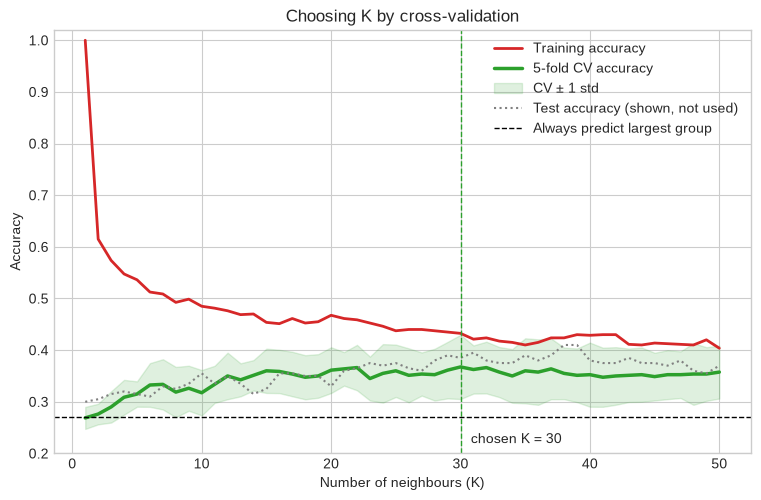

In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(results.index, results["train"], color="tab:red", linewidth=2, label="Training accuracy")
ax.plot(results.index, results["cv mean"], color="tab:green", linewidth=2.5, label="5-fold CV accuracy")
ax.fill_between(
    results.index,
    results["cv mean"] - results["cv std"],
    results["cv mean"] + results["cv std"],
    color="tab:green",
    alpha=0.15,
    label="CV ± 1 std",
)
ax.plot(
    results.index,
    results["test (not used to choose)"],
    color="grey",
    linestyle=":",
    linewidth=1.5,
    label="Test accuracy (shown, not used)",
)
ax.axhline(baseline_acc, color="black", linestyle="--", linewidth=1, label="Always predict largest group")
ax.axvline(best_k, color="tab:green", linestyle="--", linewidth=1)
ax.annotate(f"chosen K = {best_k}", (best_k + 0.8, 0.22))

ax.set_xlabel("Number of neighbours (K)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.2, 1.02)
ax.set_title("Choosing K by cross-validation")
ax.legend(loc="upper right")

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

### Final evaluation

K fixed by cross-validation, the model refitted on all 800 training customers,
and the test set used for the first and only time.

In [17]:
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_model.fit(X_train, y_train)
yhat_final = final_model.predict(X_test)

final_acc = metrics.accuracy_score(y_test, yhat_final)
print(f"K = {best_k}")
print(f"Test accuracy:     {final_acc:.4f}")
print(f"Baseline accuracy: {baseline_acc:.4f}")

K = 30
Test accuracy:     0.3850
Baseline accuracy: 0.2700


Accuracy is one number for four groups. The confusion matrix shows *which*
groups get mixed up: each row is a true group, each column a predicted one, so
the diagonal holds the correct answers.

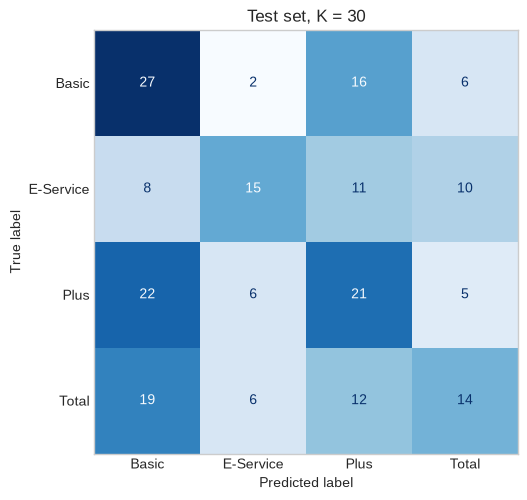

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

group_names = ["Basic", "E-Service", "Plus", "Total"]

fig, ax = plt.subplots(figsize=(6, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, yhat_final, display_labels=group_names, cmap="Blues", colorbar=False, ax=ax
)
ax.grid(False)
ax.set_title(f"Test set, K = {best_k}")
plt.show()

In [19]:
print(metrics.classification_report(y_test, yhat_final, target_names=group_names))

              precision    recall  f1-score   support

       Basic       0.36      0.53      0.43        51
   E-Service       0.52      0.34      0.41        44
        Plus       0.35      0.39      0.37        54
       Total       0.40      0.27      0.33        51

    accuracy                           0.39       200
   macro avg       0.41      0.38      0.38       200
weighted avg       0.40      0.39      0.38       200



### Reading the result

Cross-validation settles on **K = 30**, and on the test set that model scores
**0.385** against the 0.27 baseline — right on roughly two customers in five,
where ignoring the features entirely manages about one in four.

**The curves.** Training accuracy starts at a perfect 1.0 for K = 1, which is
memorisation, not learning: every training customer is its own nearest
neighbour. It falls steadily as K grows and neighbourhoods average over more
customers. Cross-validated accuracy moves the other way, climbing from 0.27 at
K = 1 and levelling out around 0.35–0.37 from about K = 15 onwards. The
narrowing gap between the two is overfitting being reduced.

**K = 30 is not special.** Beyond K = 15 the CV curve is flat, and its fold-to-
fold spread (about ±0.05) is wider than any difference between neighbouring
values of K. Any K from roughly 15 to 50 is equally defensible; 30 happens to be
the highest point of a plateau.

**What peeking would have cost.** Choosing K on the test set would have picked
K = 38 and reported 0.41. That extra 2.5 points is not a better model — it is the
best of fifty draws on the same 200 customers. With 200 test rows, one customer
is half a point of accuracy, and the typical noise in an accuracy measured on
200 rows is around ±3.4 points; differences smaller than that are not evidence
of anything. Cross-validation's honest 0.385 is the number to trust.

**Where it fails — the confusion matrix.** The model predicts *Basic* for 76 of
the 200 test customers, far more than the 51 who really are Basic. It finds most
of the true Basic customers (27 of 51) largely because it guesses Basic so
often. *Plus* customers are sent to Basic almost as often as to Plus (22 against
21), and *Total Service* customers are the worst served: only 14 of 51 are
recognised. *E-Service* predictions are the most trustworthy — when the model
says E-Service it is right about half the time.

**Why the ceiling is low.** Two reasons, one about the data and one about the
method:

- **Demographics say little about how someone uses a phone service.** The best
  any value of K reaches is around 0.37 in cross-validation. That is a property
  of the information in these eleven columns, not of the tuning.
- **KNN weights every feature equally.** The distance gives `gender` exactly the
  same say as `tenure`, and the method has no way to learn otherwise. Features
  that carry no signal still add noise to every distance and dilute the ones
  that do. Models that learn a weight per feature — logistic regression, decision
  trees — can discount useless columns; KNN cannot.

One further weakness is worth naming. `region` is a label, not a quantity, yet
it enters the distance as the numbers 1, 2 and 3 — so regions 1 and 3 count as
"further apart" than regions 1 and 2 for no real reason. One-hot encoding it, as
the Tehran project did for neighbourhoods, would remove that false ordering.

**The conclusion.** KNN does find real signal here — 0.385 against 0.27 is a
clear margin — but a weak one. Most of the lesson's value is in the method
around the model: scaling fitted on training data only, a baseline to judge
against, and a hyperparameter chosen without touching the test set.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on k-nearest neighbours,
  which uses this dataset and framing.
- Dataset: `teleCust1000t.csv`, telecommunications customer records, as
  supplied with the course.
- scikit-learn documentation: [Nearest neighbors classification](https://scikit-learn.org/stable/modules/neighbors.html#classification)
- scikit-learn documentation: [Cross-validation: evaluating estimator performance](https://scikit-learn.org/stable/modules/cross_validation.html)